# C04b — ORG Referential Explicitization

This notebook tests a higher-coverage **Step 9** intervention for the dominant
post-Step-8 FZ301 residual family, `ner_ORG_*`.

The intervention is a narrowly constrained sentence paraphrase:

> `NASA developed the instrument, which was later tested extensively.`  
> → `NASA developed the instrument, and later NASA tested it extensively.`

The operation is **referential explicitization**, not free rewriting. It may
only reuse an organization already present in the sentence/document, and each
candidate is instructed to add exactly one additional explicit occurrence of
that same organization while preserving the original propositions.

Policy:
- Treat only documents below the fixed same-genre human median of
  `ner_ORG_sentence_mean`.
- Do not invent organizations: zero-ORG documents are no-ops.
- Generate candidates only for sentences already containing a spaCy `ORG`.
- Use deterministic beam-search paraphrasing with a pinned model revision.
- Each candidate must remain one sentence, add exactly one target-ORG surface
  occurrence, increase detected ORG count, preserve all original named
  entities/numbers/verb lemmas/negation, retain >=90% of original content
  lemmas, and stay within a bounded length ratio.
- Surviving candidates are ranked with the same pinned causal-LM scorer used by
  earlier intervention stages.
- At most one rewrite is selected per original sentence.
- Frozen FZ301 is evaluated only after treatment.

In [1]:
from pathlib import Path
import json, hashlib, pickle, re, math, warnings
from collections import Counter, defaultdict
from functools import lru_cache
import importlib.metadata as importlib_metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy, textstat, sklearn
import torch
import torch.nn.functional as F
import transformers

from sklearn.metrics import roc_curve, auc
from IPython.display import display
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM
from huggingface_hub import model_info

try:
    from empath import Empath
except ImportError as e:
    raise ImportError(
        "C04b inherits the C04 `empath` dependency. "
        "Run `%pip install empath` once in this Jupyter kernel."
    ) from e

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
BASE = ROOT / "results/causal/C02d2_fz118_ghostbuster_raid"
C04_ROOT = ROOT / "results/causal/C04_fz301_raid_fixed54"
FIG = ROOT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SEED = 20260911
B = 2000

np.random.seed(SEED)
torch.manual_seed(SEED)

normalize = lambda t: str(t).replace("\n", " ").replace("\r", " ")

nlp = spacy.load("en_core_web_sm")
empath = Empath()

features = pd.read_parquet(BASE / "fz118_paired_features.parquet")
corpus = pd.read_parquet(BASE / "paired_corpus.parquet")
assert features.source_id.is_unique and corpus.source_id.is_unique

text_map = corpus.set_index("source_id").text.to_dict()
raid = features.loc[features.dataset.eq("raid")].copy().reset_index(drop=True)

c04_runs = []
for p in sorted(C04_ROOT.glob("*")):
    if not p.is_dir():
        continue
    if not (p / "FZ301.pkl").exists() or not (p / "stage_summary.csv").exists():
        continue

    s = pd.read_csv(p / "stage_summary.csv")

    if (
        len(s) == 3
        and np.isclose(float(s.iloc[0]["AUROC"]), 0.875380, atol=5e-6)
        and np.isclose(float(s.iloc[2]["AUROC"]), 0.699558, atol=5e-6)
    ):
        c04_runs.append(p)

assert len(c04_runs) == 1, (
    "Expected exactly one accepted C04 baseline matching the observed "
    "0.875380 / 0.699558 AUROCs. Found:\n"
    + "\n".join(map(str, c04_runs))
)

C04_RUN = c04_runs[0]
C04_CONTRACT = json.loads((C04_RUN / "contract.json").read_text())
C04_MANIFEST = json.loads((C04_RUN / "feature_manifest.json").read_text())

with (C04_RUN / "FZ301.pkl").open("rb") as f:
    fz301 = pickle.load(f)

POST8_PATH = ROOT / C04_CONTRACT["post8_file"]

post8 = (
    pd.read_csv(POST8_PATH, keep_default_na=False)
    .sort_values("case_id")
    .reset_index(drop=True)
)

assert len(post8) == 54
assert post8.case_id.is_unique and post8.source_id.is_unique

CACHE = (
    ROOT
    / "results/causal/C04_fz301_feature_cache"
    / C04_CONTRACT["feature_manifest_hash"]
)
assert (CACHE / "raid_extensions.parquet").exists()

human_test_manifest = pd.read_csv(C04_RUN / "human_test_manifest.csv")

ORG_FEATURES = [
    "ner_ORG_entity_share",
    "ner_ORG_sentence_mean",
    "ner_ORG_sentence_std",
    "ner_ORG_sentence_max",
]
TARGET_FEATURE = "ner_ORG_sentence_mean"

raid_ext_cache = (
    pd.read_parquet(CACHE / "raid_extensions.parquet")
    .set_index("source_id")
)

human_org = raid_ext_cache.loc[
    human_test_manifest.source_id,
    ORG_FEATURES,
].copy()
human_org["domain"] = human_test_manifest.domain.to_numpy()

human_org_medians = (
    human_org.groupby("domain")[ORG_FEATURES].median()
)

print("Accepted C04 run:", C04_RUN.relative_to(ROOT))
print("Step-8 input:", POST8_PATH.relative_to(ROOT))
display(human_org_medians)

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Accepted C04 run: results/causal/C04_fz301_raid_fixed54/d6c459f7c8a2
Step-8 input: results/causal/C03e_lexical_micro_substitution/60d5986e77d8/texts_after_lexical_scored.csv


,ner_ORG_entity_share,ner_ORG_sentence_mean,ner_ORG_sentence_std,ner_ORG_sentence_max
domain,,,,
abstracts,0.400000,0.250000,0.433013,1.0
books,0.175192,0.436508,0.476565,1.0
news,0.176471,0.277778,0.489898,1.0
recipes,0.038462,0.052632,0.223297,1.0
reddit,0.000000,0.000000,0.000000,0.0
reviews,0.162500,0.170040,0.353408,1.0
wiki,0.192308,0.727273,0.799305,2.0


In [2]:
# Exact frozen project FZ118 extractor copied forward from C03.

PUNCTUATION = [
    ("comma", ","), ("period", "."), ("colon", ":"), ("semicolon", ";"),
    ("question", "?"), ("exclamation", "!"), ("hyphen", "-"), ("quote", '"'),
    ("lparen", "("), ("rparen", ")"), ("lbracket", "["), ("rbracket", "]"),
    ("newline", "\n"),
]

google_words = [
    w.strip().lower()
    for w in (BASE / "google-10000-english.txt").read_text().splitlines()
    if w.strip()
]
GOOGLE_TOP = {n: set(google_words[:n]) for n in [100, 1000, 10000]}

def safe_div(a, b):
    return float(a) / float(b) if b else 0.0

def clean_word_tokens(span):
    return [token.text.lower() for token in span if token.is_alpha]

def clean_pos_tokens(span):
    return [token.pos_ for token in span if token.is_alpha]

def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(tuple(sequence[i:i+n]) for i in range(len(sequence) - n + 1))

def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    return float(sum((a & b).values()) / denominator)

def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)
    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))

def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(multiset_overlap(words[:i], words[i+1:], n))
    return float(np.mean(values)) if values else 0.0

def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)

def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0

def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector

FEATURE_NAMES = json.loads((BASE / "fz118_feature_contract.json").read_text())["feature_names"]
assert len(FEATURE_NAMES) == 118

def fz118_frame(texts):
    arr = np.vstack([extract_fz118(t) for t in texts])
    return pd.DataFrame(arr, columns=FEATURE_NAMES)

# Sanity check directly against unchanged RAID rows.
check_rows = raid.iloc[:5].copy()
stored = check_rows[FEATURE_NAMES].to_numpy(float)
recomputed = fz118_frame([
    normalize(text_map[sid])
    for sid in check_rows["source_id"]
]).to_numpy(float)

np.testing.assert_allclose(recomputed, stored, atol=1e-9, rtol=0)
print("✓ Exact FZ118 extractor sanity check passed.")

✓ Exact FZ118 extractor sanity check passed.


In [3]:
# Freeze the project FZ301 v1 feature contract: 186 inherited + 115 new = 301.

POS_TAGS = [
    "ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET", "INTJ", "NOUN", "NUM",
    "PART", "PRON", "PROPN", "PUNCT", "SCONJ", "SYM", "VERB", "X"
]
POS_STATS = ["token_share", "sentence_mean", "sentence_std", "sentence_max"]
POS_NAMES = [f"pos_{tag}_{stat}" for tag in POS_TAGS for stat in POS_STATS]
assert len(POS_NAMES) == 68

NER_LABELS = list(nlp.get_pipe("ner").labels)
assert len(NER_LABELS) == 18, (
    f"Expected the frozen en_core_web_sm 18-label NER inventory, got {NER_LABELS}"
)
NER_STATS = ["entity_share", "sentence_mean", "sentence_std", "sentence_max"]
NER_NAMES = [f"ner_{label}_{stat}" for label in NER_LABELS for stat in NER_STATS]
assert len(NER_NAMES) == 72

COREF_NAMES = [
    "coref_mentions_per_sentence",
    "coref_clusters_per_sentence",
    "coref_repeated_clusters_per_sentence",
    "coref_repeated_cluster_share",
    "coref_repeated_mention_share",
    "coref_cluster_size_mean",
    "coref_cluster_size_std",
    "coref_cluster_size_max",
    "coref_distinct_sentence_mean",
    "coref_cross_sentence_cluster_share",
]
assert len(COREF_NAMES) == 10

GRID_ROLES = ["S", "O", "X", "-"]
GRID_NAMES = [f"entity_grid_{a}_{b}" for a in GRID_ROLES for b in GRID_ROLES]
assert len(GRID_NAMES) == 16

EMPATH_NAMES = [
    "empath_all_mean", "empath_all_median", "empath_all_min",
    "empath_all_max", "empath_all_var",
    "empath_active_mean", "empath_active_median", "empath_active_min",
    "empath_active_max", "empath_active_var",
    "empath_q10", "empath_q25", "empath_q75", "empath_q90",
    "empath_active_share",
]
assert len(EMPATH_NAMES) == 15

Q_NAMES = ["yule_q_mean"]
TOPIC_NAMES = ["topic_redundancy_mean_cosine"]

NEW115_NAMES = NER_NAMES + COREF_NAMES + GRID_NAMES + EMPATH_NAMES + Q_NAMES + TOPIC_NAMES
assert len(NEW115_NAMES) == 115 and len(set(NEW115_NAMES)) == 115

F186 = FEATURE_NAMES + POS_NAMES
F301 = F186 + NEW115_NAMES
assert len(F301) == 301 and len(set(F301)) == 301

EMPATH_CATS = sorted(empath.cats.keys())
assert len(EMPATH_CATS) >= 190

def pos_vector(doc):
    tokens = [t for t in doc if not t.is_space]
    assert {t.pos_ for t in tokens} <= set(POS_TAGS), "Unexpected POS label"
    counts = Counter(t.pos_ for t in tokens)
    sentences = [
        Counter(t.pos_ for t in s if not t.is_space)
        for s in doc.sents
        if any(not t.is_space for t in s)
    ]
    out = []
    for tag in POS_TAGS:
        a = np.asarray([s[tag] for s in sentences], dtype=float)
        out.extend([
            counts[tag] / max(len(tokens), 1),
            a.mean() if len(a) else 0.0,
            a.std(ddof=0) if len(a) else 0.0,
            a.max() if len(a) else 0.0,
        ])
    assert len(out) == 68
    return out

def ner_vector(doc):
    sentences = [s for s in doc.sents if any(not t.is_space for t in s)]
    ents = list(doc.ents)
    total_ents = len(ents)
    overall = Counter(e.label_ for e in ents)

    sent_counts = []
    for sent in sentences:
        c = Counter(
            ent.label_
            for ent in ents
            if ent.start >= sent.start and ent.end <= sent.end
        )
        sent_counts.append(c)

    out = []
    for label in NER_LABELS:
        a = np.asarray([c[label] for c in sent_counts], dtype=float)
        out.extend([
            overall[label] / max(total_ents, 1),
            a.mean() if len(a) else 0.0,
            a.std(ddof=0) if len(a) else 0.0,
            a.max() if len(a) else 0.0,
        ])
    assert len(out) == 72
    return out

def noun_chunk_key(span):
    # Identity-based proxy: remove determiners/stop words where possible and lemmatize.
    content = [
        t.lemma_.lower()
        for t in span
        if t.is_alpha and not t.is_stop and t.pos_ not in {"DET"}
    ]
    if not content:
        content = [t.lemma_.lower() for t in span if t.is_alpha]
    return " ".join(content).strip()

def grammatical_role(span):
    dep = span.root.dep_.lower()
    if dep in {"nsubj", "nsubjpass", "csubj", "csubjpass"}:
        return "S"
    if dep in {"obj", "dobj", "iobj", "pobj", "dative", "attr", "oprd"}:
        return "O"
    return "X"

def identity_mentions(doc):
    sentences = [s for s in doc.sents if any(not t.is_space for t in s)]
    token_to_sent = {}
    for j, sent in enumerate(sentences):
        for t in sent:
            token_to_sent[t.i] = j

    mentions = []
    for chunk in doc.noun_chunks:
        key = noun_chunk_key(chunk)
        if not key:
            continue
        sent_idx = token_to_sent.get(chunk.root.i)
        if sent_idx is None:
            continue
        mentions.append((key, sent_idx, grammatical_role(chunk)))
    return sentences, mentions

def coref_proxy_vector(doc):
    sentences, mentions = identity_mentions(doc)
    clusters = defaultdict(list)
    for key, sent_idx, role in mentions:
        clusters[key].append((sent_idx, role))

    sizes = np.asarray([len(v) for v in clusters.values()], dtype=float)
    repeated = [v for v in clusters.values() if len(v) > 1]
    repeated_mentions = sum(len(v) for v in repeated)
    distinct_sentence_counts = np.asarray(
        [len({s for s, _ in v}) for v in clusters.values()],
        dtype=float,
    )
    cross_sentence = sum(len({s for s, _ in v}) > 1 for v in clusters.values())

    ns = max(len(sentences), 1)
    nc = len(clusters)
    nm = len(mentions)

    out = [
        nm / ns,
        nc / ns,
        len(repeated) / ns,
        safe_div(len(repeated), nc),
        safe_div(repeated_mentions, nm),
        sizes.mean() if len(sizes) else 0.0,
        sizes.std(ddof=0) if len(sizes) else 0.0,
        sizes.max() if len(sizes) else 0.0,
        distinct_sentence_counts.mean() if len(distinct_sentence_counts) else 0.0,
        safe_div(cross_sentence, nc),
    ]
    assert len(out) == 10
    return out

def entity_grid_vector(doc):
    sentences, mentions = identity_mentions(doc)
    n_sent = len(sentences)
    keys = sorted({k for k, _, _ in mentions})
    if n_sent < 2 or not keys:
        return [0.0] * 16

    # If an identity has multiple mentions in one sentence, keep the strongest role.
    precedence = {"S": 3, "O": 2, "X": 1}
    roles = {k: ["-"] * n_sent for k in keys}
    for key, sent_idx, role in mentions:
        old = roles[key][sent_idx]
        if old == "-" or precedence[role] > precedence.get(old, 0):
            roles[key][sent_idx] = role

    counts = Counter()
    for key in keys:
        row = roles[key]
        for a, b in zip(row[:-1], row[1:]):
            counts[(a, b)] += 1

    total = sum(counts.values())
    out = [safe_div(counts[(a, b)], total) for a in GRID_ROLES for b in GRID_ROLES]
    assert len(out) == 16
    return out

def empath_vector(text):
    scores = empath.analyze(str(text), categories=EMPATH_CATS, normalize=True)
    vals = np.asarray([float(scores[c]) for c in EMPATH_CATS], dtype=float)
    active = vals[vals > 0]

    all_stats = [
        vals.mean(), np.median(vals), vals.min(), vals.max(), vals.var(ddof=0)
    ] if len(vals) else [0.0] * 5
    active_stats = [
        active.mean(), np.median(active), active.min(), active.max(), active.var(ddof=0)
    ] if len(active) else [0.0] * 5

    quantiles = (
        np.quantile(vals, [0.10, 0.25, 0.75, 0.90]).tolist()
        if len(vals) else [0.0] * 4
    )
    out = all_stats + active_stats + quantiles + [safe_div(len(active), len(vals))]
    assert len(out) == 15
    return out

def content_sentence_sets(doc):
    out = []
    for sent in doc.sents:
        s = {
            t.lemma_.lower()
            for t in sent
            if t.is_alpha and not t.is_stop and t.pos_ in {"NOUN", "PROPN", "VERB", "ADJ", "ADV"}
        }
        if s:
            out.append(s)
    return out

def yule_q_mean(doc, max_terms=40):
    # Sentence-level Yule association over the most frequent content lemmas.
    sentence_sets = content_sentence_sets(doc)
    n = len(sentence_sets)
    if n < 2:
        return 0.0

    freq = Counter(w for s in sentence_sets for w in s)
    terms = [w for w, _ in sorted(freq.items(), key=lambda kv: (-kv[1], kv[0]))[:max_terms]]
    if len(terms) < 2:
        return 0.0

    present = {w: np.asarray([w in s for s in sentence_sets], dtype=bool) for w in terms}
    qs = []
    for i, a in enumerate(terms):
        A = present[a]
        for b in terms[i+1:]:
            B = present[b]
            n11 = int(np.sum(A & B))
            n10 = int(np.sum(A & ~B))
            n01 = int(np.sum(~A & B))
            n00 = int(np.sum(~A & ~B))
            den = n11 * n00 + n10 * n01
            if den:
                qs.append((n11 * n00 - n10 * n01) / den)
    return float(np.mean(qs)) if qs else 0.0

def topic_redundancy_mean_cosine(doc):
    # Pairwise cosine over sentence content-lemma count vectors.
    counters = []
    for sent in doc.sents:
        c = Counter(
            t.lemma_.lower()
            for t in sent
            if t.is_alpha and not t.is_stop and t.pos_ in {"NOUN", "PROPN", "VERB", "ADJ", "ADV"}
        )
        if c:
            counters.append(c)

    if len(counters) < 2:
        return 0.0

    norms = [math.sqrt(sum(v * v for v in c.values())) for c in counters]
    sims = []
    for i, a in enumerate(counters):
        for j in range(i + 1, len(counters)):
            b = counters[j]
            dot = sum(v * b.get(k, 0) for k, v in a.items())
            denom = norms[i] * norms[j]
            sims.append(dot / denom if denom else 0.0)
    return float(np.mean(sims)) if sims else 0.0

def extension_vector(doc):
    out = (
        pos_vector(doc)
        + ner_vector(doc)
        + coref_proxy_vector(doc)
        + entity_grid_vector(doc)
        + empath_vector(doc.text)
        + [yule_q_mean(doc)]
        + [topic_redundancy_mean_cosine(doc)]
    )
    arr = np.asarray(out, dtype=np.float64)
    assert arr.shape == (183,)
    assert np.isfinite(arr).all()
    return arr

EXT_NAMES = POS_NAMES + NEW115_NAMES
assert len(EXT_NAMES) == 183

# C04b inherits the exact frozen C04 feature ordering/definitions.
assert F301 == list(C04_MANIFEST["feature_names"])
assert len(F301) == 301
print("✓ FZ301 feature functions loaded; exact C04 manifest ordering preserved.")

✓ FZ301 feature functions loaded; exact C04 manifest ordering preserved.


In [4]:
# Resolve/pin Qwen paraphraser + scorer and freeze the C04b contract.

PARAPHRASER_ID = "Qwen/Qwen2.5-1.5B-Instruct"
PARAPHRASER_REVISION = model_info(PARAPHRASER_ID).sha

SCORER_CONTRACT = (
    ROOT
    / "results/causal/C02r_discovery_gated_punctuation/treatment_contract.json"
)
assert SCORER_CONTRACT.exists(), SCORER_CONTRACT

scorer_meta = json.loads(SCORER_CONTRACT.read_text())
SCORER_ID = scorer_meta["scorer"]
SCORER_REVISION = scorer_meta["scorer_revision"]

assert SCORER_REVISION and SCORER_REVISION != "main"

STEP9_CFG = {
    "target_feature": TARGET_FEATURE,
    "target": "same-genre fixed test-human median",
    "operation": "ORG referential explicitization by constrained sentence paraphrase",
    "paraphraser": PARAPHRASER_ID,
    "paraphraser_revision": PARAPHRASER_REVISION,
    "num_beams": 8,
    "num_return_sequences": 8,
    "max_new_tokens": 128,
    "do_sample": False,
    "max_sentence_edits_per_case": 8,
    "max_prompts_per_case": 24,
    "min_content_lemma_recall": 0.90,
    "max_added_content_lemmas": 4,
    "min_length_ratio": 0.75,
    "max_length_ratio": 1.35,
    "left_words": 48,
    "right_words": 32,
    "min_local_mean_logp_delta": -1.5,
    "seed": SEED,
}

contract = {
    "name": "C04b_ORG_referential_explicitization_qwen_v2",
    "config": STEP9_CFG,
    "parent_C04_run": str(C04_RUN.relative_to(ROOT)),
    "parent_C04_contract_sha256": hashlib.sha256(
        (C04_RUN / "contract.json").read_bytes()
    ).hexdigest(),
    "input_step8": str(POST8_PATH.relative_to(ROOT)),
    "input_step8_sha256": hashlib.sha256(
        POST8_PATH.read_bytes()
    ).hexdigest(),
    "scorer": SCORER_ID,
    "scorer_revision": SCORER_REVISION,
    "scorer_contract": str(
        SCORER_CONTRACT.relative_to(ROOT)
    ),
    "spacy": nlp.meta,
    "transformers": transformers.__version__,
    "torch": torch.__version__,
}

RUN_HASH = hashlib.sha256(
    json.dumps(
        contract,
        sort_keys=True,
        default=str,
    ).encode()
).hexdigest()[:12]

OUT = (
    ROOT
    / "results/causal/C04b_ORG_referential_explicitization"
    / RUN_HASH
)

OUT.mkdir(
    parents=True,
    exist_ok=True,
)

(OUT / "contract.json").write_text(
    json.dumps(
        contract,
        indent=2,
        default=str,
    )
)

print(
    "C04b output:",
    OUT.relative_to(ROOT),
)

print(
    "Paraphraser:",
    PARAPHRASER_ID,
)

print(
    "Paraphraser revision:",
    PARAPHRASER_REVISION,
)

print(
    "Scorer:",
    SCORER_ID,
)

print(
    "Scorer revision:",
    SCORER_REVISION,
)

C04b output: results/causal/C04b_ORG_referential_explicitization/c3a89a200711
Paraphraser: Qwen/Qwen2.5-1.5B-Instruct
Paraphraser revision: 989aa7980e4cf806f80c7fef2b1adb7bc71aa306
Scorer: gpt2
Scorer revision: 607a30d783dfa663caf39e06633721c8d4cfcd7e


In [5]:
# Candidate-generation helpers and strict structural/semantic guards.

NUMBER_RE = re.compile(
    r"\b\d[\d,./:%-]*\b"
)

NEG_WORDS = {
    "no",
    "not",
    "n't",
    "never",
    "neither",
    "nor",
}

CONTENT_POS = {
    "NOUN",
    "PROPN",
    "VERB",
    "ADJ",
    "ADV",
    "NUM",
}

PROMPT_LEAK_PATTERNS = [
    r"\borganization\s*:",
    r"\binput\s*:",
    r"\boutput\s*:",
    r"\brequirements\s*:",
    r"\brewritten sentence\s*:",
    r"\bexplanation\s*:",
]


def org_stats(text):

    doc = nlp(
        str(text)
    )

    sentences = [
        s
        for s in doc.sents
        if any(
            not t.is_space
            for t in s
        )
    ]

    ents = list(
        doc.ents
    )

    orgs = [
        e
        for e in ents
        if e.label_ == "ORG"
    ]

    per_sentence = [
        sum(
            e.start >= sent.start
            and e.end <= sent.end
            for e in orgs
        )
        for sent in sentences
    ]

    a = np.asarray(
        per_sentence,
        dtype=float,
    )

    return {
        "n_sentences":
            len(sentences),

        "n_entities":
            len(ents),

        "n_org":
            len(orgs),

        "ner_ORG_entity_share":
            safe_div(
                len(orgs),
                len(ents),
            ),

        "ner_ORG_sentence_mean":
            a.mean()
            if len(a)
            else 0.0,

        "ner_ORG_sentence_std":
            a.std(ddof=0)
            if len(a)
            else 0.0,

        "ner_ORG_sentence_max":
            a.max()
            if len(a)
            else 0.0,
    }


def norm_surface(s):

    return re.sub(
        r"\s+",
        " ",
        str(s).strip().lower(),
    )


def exact_surface_count(
    text,
    surface,
):

    return len(
        re.findall(
            re.escape(
                surface
            ),
            str(text),
            flags=re.IGNORECASE,
        )
    )


def content_lemmas(doc):

    return Counter(
        t.lemma_.lower()
        for t in doc
        if (
            t.is_alpha
            and not t.is_stop
            and t.pos_
            in CONTENT_POS
        )
    )


def verb_lemmas(doc):

    return Counter(
        t.lemma_.lower()
        for t in doc
        if t.pos_
        == "VERB"
    )


def negations(doc):

    return Counter(
        t.text.lower()
        for t in doc
        if (
            t.dep_.lower()
            == "neg"
            or t.text.lower()
            in NEG_WORDS
        )
    )


def named_entity_surfaces(
    doc,
):

    return Counter(
        norm_surface(
            e.text
        )
        for e in doc.ents
    )


def org_surfaces(doc):

    return Counter(
        norm_surface(
            e.text
        )
        for e in doc.ents
        if e.label_
        == "ORG"
    )


def candidate_guard(
    source_sentence,
    candidate_sentence,
    target_org,
):

    source_sentence = (
        str(
            source_sentence
        ).strip()
    )

    candidate_sentence = (
        str(
            candidate_sentence
        ).strip()
    )

    result = {
        "valid":
            False,

        "rejection_reason":
            "",
    }


    if not candidate_sentence:

        result[
            "rejection_reason"
        ] = "empty"

        return result


    if "\n" in candidate_sentence:

        result[
            "rejection_reason"
        ] = "newline"

        return result


    if any(
        re.search(
            pattern,
            candidate_sentence,
            flags=re.IGNORECASE,
        )
        for pattern
        in PROMPT_LEAK_PATTERNS
    ):

        result[
            "rejection_reason"
        ] = "prompt_leak"

        return result


    sdoc = nlp(
        source_sentence
    )

    cdoc = nlp(
        candidate_sentence
    )


    s_sents = [
        s
        for s in sdoc.sents
        if s.text.strip()
    ]

    c_sents = [
        s
        for s in cdoc.sents
        if s.text.strip()
    ]


    if (
        len(s_sents) != 1
        or len(c_sents) != 1
    ):

        result[
            "rejection_reason"
        ] = "sentence_count_changed"

        return result


    source_target_count = (
        exact_surface_count(
            source_sentence,
            target_org,
        )
    )

    candidate_target_count = (
        exact_surface_count(
            candidate_sentence,
            target_org,
        )
    )


    if (
        candidate_target_count
        != source_target_count + 1
    ):

        result[
            "rejection_reason"
        ] = "target_surface_not_plus_one"

        return result


    s_org_count = sum(
        e.label_ == "ORG"
        for e in sdoc.ents
    )

    c_org_count = sum(
        e.label_ == "ORG"
        for e in cdoc.ents
    )


    if (
        c_org_count
        <= s_org_count
    ):

        result[
            "rejection_reason"
        ] = "detected_ORG_not_increased"

        return result


    s_ents = (
        named_entity_surfaces(
            sdoc
        )
    )

    c_ents = (
        named_entity_surfaces(
            cdoc
        )
    )


    for (
        surface,
        count,
    ) in s_ents.items():

        if (
            c_ents[
                surface
            ]
            < count
        ):

            result[
                "rejection_reason"
            ] = (
                f"lost_entity:"
                f"{surface}"
            )

            return result


    target_norm = (
        norm_surface(
            target_org
        )
    )


    for surface in c_ents:

        if (
            surface
            not in s_ents
            and surface
            != target_norm
        ):

            result[
                "rejection_reason"
            ] = (
                f"new_entity:"
                f"{surface}"
            )

            return result


    s_orgs = set(
        org_surfaces(
            sdoc
        )
    )

    c_orgs = set(
        org_surfaces(
            cdoc
        )
    )


    if not c_orgs <= (
        s_orgs
        | {
            target_norm
        }
    ):

        result[
            "rejection_reason"
        ] = (
            "new_ORG_identity"
        )

        return result


    if (
        Counter(
            NUMBER_RE.findall(
                source_sentence
            )
        )
        !=
        Counter(
            NUMBER_RE.findall(
                candidate_sentence
            )
        )
    ):

        result[
            "rejection_reason"
        ] = "numbers_changed"

        return result


    s_verbs = (
        verb_lemmas(
            sdoc
        )
    )

    c_verbs = (
        verb_lemmas(
            cdoc
        )
    )


    for (
        lemma,
        count,
    ) in s_verbs.items():

        if (
            c_verbs[
                lemma
            ]
            < count
        ):

            result[
                "rejection_reason"
            ] = (
                f"lost_verb:"
                f"{lemma}"
            )

            return result


    if (
        negations(
            sdoc
        )
        != negations(
            cdoc
        )
    ):

        result[
            "rejection_reason"
        ] = (
            "negation_changed"
        )

        return result


    s_content = (
        content_lemmas(
            sdoc
        )
    )

    c_content = (
        content_lemmas(
            cdoc
        )
    )


    total_content = sum(
        s_content.values()
    )


    overlap = sum(
        min(
            count,
            c_content[
                lemma
            ],
        )
        for (
            lemma,
            count,
        )
        in s_content.items()
    )


    recall = (
        overlap
        / total_content
        if total_content
        else 1.0
    )


    if (
        recall
        < STEP9_CFG[
            "min_content_lemma_recall"
        ]
    ):

        result[
            "rejection_reason"
        ] = (
            "content_recall_low"
        )

        result[
            "content_lemma_recall"
        ] = recall

        return result


    added = sum(
        max(
            0,
            count
            - s_content[
                lemma
            ],
        )
        for (
            lemma,
            count,
        )
        in c_content.items()
    )


    if (
        added
        > STEP9_CFG[
            "max_added_content_lemmas"
        ]
    ):

        result[
            "rejection_reason"
        ] = (
            "too_many_added_content_lemmas"
        )

        result[
            "added_content_lemmas"
        ] = added

        return result


    source_len = max(
        1,
        len(
            source_sentence.split()
        ),
    )

    candidate_len = len(
        candidate_sentence.split()
    )

    length_ratio = (
        candidate_len
        / source_len
    )


    if not (
        STEP9_CFG[
            "min_length_ratio"
        ]
        <= length_ratio
        <= STEP9_CFG[
            "max_length_ratio"
        ]
    ):

        result[
            "rejection_reason"
        ] = (
            "length_ratio"
        )

        result[
            "length_ratio"
        ] = (
            length_ratio
        )

        return result


    result.update({
        "valid":
            True,

        "rejection_reason":
            "",

        "source_ORG_count":
            s_org_count,

        "candidate_ORG_count":
            c_org_count,

        "content_lemma_recall":
            recall,

        "added_content_lemmas":
            added,

        "length_ratio":
            length_ratio,
    })


    return result


def make_prompt(
    sentence,
    org,
):

    return f"""
Edit only the sentence below.

Return ONLY the rewritten sentence. Do not add labels, commentary, quotes, or explanation.

Your one required edit:
- The exact organization name "{org}" already appears in the sentence.
- Write the exact string "{org}" exactly ONE additional time.
- Use that extra occurrence to make a later implicit, pronominal, passive, or relative reference to the same organization explicit.

Preserve everything else as closely as possible:
- preserve every fact and relation;
- preserve every name, number, date, negation, tense, and modality;
- preserve the original verbs whenever possible;
- keep exactly one sentence;
- introduce no new entity or fact;
- prefer a direct active rewrite.

Preferred pattern:
NASA developed the instrument, which was later tested extensively.
-> NASA developed the instrument, and later NASA tested it extensively.

Sentence:
{sentence}

Organization to repeat exactly once:
{org}
""".strip()


prompt_rows = []


for row in post8.itertuples(
    index=False
):

    before = org_stats(
        row.text
    )

    target = float(
        human_org_medians.loc[
            row.domain,
            TARGET_FEATURE,
        ]
    )


    if (
        before[
            TARGET_FEATURE
        ]
        >= target
        - 1e-12
    ):
        continue


    doc = nlp(
        str(
            row.text
        )
    )


    for (
        sent_idx,
        sent,
    ) in enumerate(
        doc.sents
    ):

        seen_org = set()


        for ent in doc.ents:

            if not (
                ent.label_
                == "ORG"
                and ent.start
                >= sent.start
                and ent.end
                <= sent.end
            ):
                continue


            org = ent.text

            key = (
                norm_surface(
                    org
                )
            )


            if key in seen_org:
                continue


            seen_org.add(
                key
            )


            prompt_rows.append({
                "case_id":
                    row.case_id,

                "source_id":
                    row.source_id,

                "domain":
                    row.domain,

                "sentence_index":
                    sent_idx,

                "sentence_start":
                    sent.start_char,

                "sentence_end":
                    sent.end_char,

                "source_sentence":
                    sent.text,

                "target_org":
                    org,

                "target_ORG_sentence_mean":
                    target,

                "prompt":
                    make_prompt(
                        sent.text,
                        org,
                    ),
            })


prompt_manifest = pd.DataFrame(
    prompt_rows
)


if len(
    prompt_manifest
):

    prompt_manifest = (
        prompt_manifest
        .sort_values(
            [
                "case_id",
                "sentence_index",
                "target_org",
            ]
        )
        .groupby(
            "case_id",
            group_keys=False,
        )
        .head(
            STEP9_CFG[
                "max_prompts_per_case"
            ]
        )
        .reset_index(
            drop=True
        )
    )


prompt_manifest.to_csv(
    OUT
    / "prompt_manifest.csv",
    index=False,
)


n_below = sum(
    org_stats(
        row.text
    )[
        TARGET_FEATURE
    ]
    < float(
        human_org_medians.loc[
            row.domain,
            TARGET_FEATURE,
        ]
    )
    - 1e-12
    for row
    in post8.itertuples(
        index=False
    )
)


print(
    "Below-target documents:",
    int(
        n_below
    ),
)


print(
    "Promptable cases:",
    (
        prompt_manifest.case_id.nunique()
        if len(
            prompt_manifest
        )
        else 0
    ),
)


print(
    "Total prompts:",
    len(
        prompt_manifest
    ),
)


if len(
    prompt_manifest
):

    display(
        prompt_manifest[
            [
                "case_id",
                "domain",
                "sentence_index",
                "target_org",
                "source_sentence",
            ]
        ].head(
            30
        )
    )

Below-target documents: 26
Promptable cases: 12
Total prompts: 49


,case_id,domain,sentence_index,target_org,source_sentence
0,gate_0007,wiki,2,Treasury,Sir John Maitland was a member of a prominent ...
1,gate_0007,wiki,3,the Union of the Crowns of Scotland,He played a key role in negotiations leading t...
2,gate_0007,wiki,4,the Scottish Privy Council,The 1st Viscount of Oxfuird was succeeded by h...
3,gate_0007,wiki,5,3rd Viscount,"The 2nd Viscount's son, Charles Maitland, 3rd ..."
4,gate_0007,wiki,5,Viscount,"The 2nd Viscount's son, Charles Maitland, 3rd ..."
5,gate_0007,wiki,6,The 3rd Viscount's,"The 3rd Viscount's son, John Maitland, 4th Vis..."
6,gate_0007,wiki,6,the British Parliament,"The 3rd Viscount's son, John Maitland, 4th Vis..."
7,gate_0007,wiki,10,the National Library of,And his collection is now housed in the Nation...
8,gate_0007,wiki,11,the British Parliament,"The 5th Viscount's son John Maitland, 6th Visc..."
9,gate_0007,wiki,14,the National Library of,He was also a noted collector of art and rare ...


In [6]:
# Deterministically generate Qwen paraphrase candidates and apply guards.

GENERATED_PATH = (
    OUT
    / "generated_candidates.csv"
)


if GENERATED_PATH.exists():

    generated_candidates = (
        pd.read_csv(
            GENERATED_PATH,
            keep_default_na=False,
        )
    )

    print(
        "✓ Reusing cached Qwen paraphrase candidates:",
        GENERATED_PATH.relative_to(
            ROOT
        ),
    )


else:

    gen_device = (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )


    para_tokenizer = (
        AutoTokenizer.from_pretrained(
            PARAPHRASER_ID,
            revision=PARAPHRASER_REVISION,
            use_fast=True,
        )
    )


    if (
        para_tokenizer.pad_token_id
        is None
    ):

        para_tokenizer.pad_token = (
            para_tokenizer.eos_token
        )


    para_dtype = (
        torch.float16
        if gen_device
        == "cuda"
        else torch.float32
    )


    paraphraser = (
        AutoModelForCausalLM.from_pretrained(
            PARAPHRASER_ID,
            revision=PARAPHRASER_REVISION,
            torch_dtype=para_dtype,
            low_cpu_mem_usage=True,
        )
    )


    paraphraser.to(
        gen_device
    ).eval()


    system_message = (
        "You are a precise text editor. "
        "Follow the requested sentence edit exactly. "
        "Return only the rewritten sentence and nothing else."
    )


    rows = []


    for (
        prompt_i,
        p,
    ) in enumerate(
        prompt_manifest.itertuples(
            index=False
        ),
        start=1,
    ):

        messages = [
            {
                "role":
                    "system",

                "content":
                    system_message,
            },
            {
                "role":
                    "user",

                "content":
                    p.prompt,
            },
        ]


        prompt_text = (
            para_tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True,
            )
        )


        enc = para_tokenizer(
            prompt_text,
            return_tensors="pt",
            add_special_tokens=False,
            truncation=False,
        )


        model_ctx = getattr(
            paraphraser.config,
            "max_position_embeddings",
            None,
        )


        if model_ctx is None:

            model_ctx = getattr(
                para_tokenizer,
                "model_max_length",
                32768,
            )


        if (
            model_ctx is None
            or model_ctx
            > 1000000
        ):

            model_ctx = 32768


        if (
            enc[
                "input_ids"
            ].shape[1]
            + STEP9_CFG[
                "max_new_tokens"
            ]
            > model_ctx
        ):

            rows.append({
                "case_id":
                    p.case_id,

                "source_id":
                    p.source_id,

                "domain":
                    p.domain,

                "sentence_index":
                    p.sentence_index,

                "sentence_start":
                    p.sentence_start,

                "sentence_end":
                    p.sentence_end,

                "source_sentence":
                    p.source_sentence,

                "target_org":
                    p.target_org,

                "candidate_rank":
                    -1,

                "candidate_sentence":
                    "",

                "valid":
                    False,

                "rejection_reason":
                    "prompt_too_long",
            })

            continue


        enc = {
            k:
                v.to(
                    gen_device
                )
            for (
                k,
                v,
            )
            in enc.items()
        }


        input_len = (
            enc[
                "input_ids"
            ].shape[1]
        )


        with torch.inference_mode():

            out_ids = (
                paraphraser.generate(
                    **enc,
                    num_beams=STEP9_CFG[
                        "num_beams"
                    ],
                    num_return_sequences=STEP9_CFG[
                        "num_return_sequences"
                    ],
                    max_new_tokens=STEP9_CFG[
                        "max_new_tokens"
                    ],
                    do_sample=False,
                    early_stopping=True,
                    pad_token_id=para_tokenizer.pad_token_id,
                    eos_token_id=para_tokenizer.eos_token_id,
                )
            )


        # Qwen is causal: decode only tokens after the prompt.
        generated_only = (
            out_ids[
                :,
                input_len:
            ]
        )


        decoded = (
            para_tokenizer.batch_decode(
                generated_only,
                skip_special_tokens=True,
                clean_up_tokenization_spaces=True,
            )
        )


        seen = set()
        unique = []


        for candidate in decoded:

            candidate = (
                candidate.strip()
            )


            # Strip one layer of wrapping quotes only.
            if (
                len(candidate)
                >= 2
                and candidate[0]
                == candidate[-1]
                and candidate[0]
                in {
                    '"',
                    "'",
                }
            ):

                candidate = (
                    candidate[
                        1:-1
                    ].strip()
                )


            if candidate in seen:
                continue


            seen.add(
                candidate
            )

            unique.append(
                candidate
            )


        for (
            rank,
            candidate,
        ) in enumerate(
            unique,
            start=1,
        ):

            guard = (
                candidate_guard(
                    p.source_sentence,
                    candidate,
                    p.target_org,
                )
            )


            rows.append({
                "case_id":
                    p.case_id,

                "source_id":
                    p.source_id,

                "domain":
                    p.domain,

                "sentence_index":
                    p.sentence_index,

                "sentence_start":
                    p.sentence_start,

                "sentence_end":
                    p.sentence_end,

                "source_sentence":
                    p.source_sentence,

                "target_org":
                    p.target_org,

                "candidate_rank":
                    rank,

                "candidate_sentence":
                    candidate,

                **guard,
            })


        if (
            prompt_i
            % 10
            == 0
            or prompt_i
            == len(
                prompt_manifest
            )
        ):

            print(
                f"Generated "
                f"{prompt_i}/"
                f"{len(prompt_manifest)} "
                f"prompts"
            )


    generated_candidates = (
        pd.DataFrame(
            rows
        )
    )


    generated_candidates.to_csv(
        GENERATED_PATH,
        index=False,
    )


    del paraphraser


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


print(
    "\nCandidate guard summary:"
)


if len(
    generated_candidates
):

    display(
        generated_candidates[
            "valid"
        ]
        .value_counts(
            dropna=False
        )
        .rename_axis(
            "valid"
        )
        .to_frame(
            "n"
        )
    )


    print(
        "\nTop rejection reasons:"
    )


    display(
        generated_candidates.loc[
            ~generated_candidates[
                "valid"
            ].astype(
                bool
            ),
            "rejection_reason",
        ]
        .value_counts()
        .head(
            20
        )
        .rename_axis(
            "reason"
        )
        .to_frame(
            "n"
        )
    )


valid_candidates = (
    generated_candidates.loc[
        generated_candidates[
            "valid"
        ].astype(
            bool
        )
    ]
    .copy()
)


print(
    "\nCases with at least one valid candidate:",
    (
        valid_candidates.case_id.nunique()
        if len(
            valid_candidates
        )
        else 0
    ),
)


if len(
    valid_candidates
):

    display(
        valid_candidates[
            [
                "case_id",
                "domain",
                "sentence_index",
                "target_org",
                "source_sentence",
                "candidate_sentence",
                "content_lemma_recall",
                "length_ratio",
            ]
        ].head(
            40
        )
    )

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 579.98it/s]
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Generated 10/49 prompts
Generated 20/49 prompts
Generated 30/49 prompts
Generated 40/49 prompts
Generated 49/49 prompts

Candidate guard summary:


,n
valid,
False,353
True,38



Top rejection reasons:


,n
reason,
target_surface_not_plus_one,270
detected_ORG_not_increased,23
length_ratio,15
sentence_count_changed,14
too_many_added_content_lemmas,9
new_entity:later blue merle,4
newline,2
lost_entity:3rd,2
new_entity:the national library of scotland,2



Cases with at least one valid candidate: 8


,case_id,domain,sentence_index,target_org,source_sentence,candidate_sentence,content_lemma_recall,length_ratio
10,gate_0007,wiki,3,the Union of the Crowns of Scotland,He played a key role in negotiations leading t...,He played a key role in negotiations leading t...,1.000000,1.333333
67,gate_0007,wiki,11,the British Parliament,"The 5th Viscount's son John Maitland, 6th Visc...","The 5th Viscount's son John Maitland, 6th Visc...",1.000000,1.115385
115,gate_0027,wiki,0,Angus,The Fife Coalfield was a significant coal mini...,The Fife Coalfield was a significant coal mini...,1.000000,1.083333
116,gate_0027,wiki,0,Angus,The Fife Coalfield was a significant coal mini...,The Fife Coalfield was a significant coal mini...,1.000000,1.166667
129,gate_0027,wiki,7,Newtongrange,The Scottish Mining Museum in Newtongrange att...,The Scottish Mining Museum in Newtongrange att...,0.933333,0.964286
130,gate_0027,wiki,7,Newtongrange,The Scottish Mining Museum in Newtongrange att...,The Scottish Mining Museum in Newtongrange att...,1.000000,1.107143
131,gate_0027,wiki,7,Newtongrange,The Scottish Mining Museum in Newtongrange att...,The Scottish Mining Museum in Newtongrange att...,1.000000,1.035714
132,gate_0027,wiki,7,Newtongrange,The Scottish Mining Museum in Newtongrange att...,The Scottish Mining Museum in Newtongrange att...,1.000000,1.107143
135,gate_0027,wiki,7,Newtongrange,The Scottish Mining Museum in Newtongrange att...,The Scottish Mining Museum in Newtongrange att...,1.000000,1.107143
138,gate_0027,wiki,7,The Scottish Mining Museum,The Scottish Mining Museum in Newtongrange att...,The Scottish Mining Museum in Newtongrange att...,1.000000,1.214286


In [7]:
# Likelihood-rank valid candidates and select sentence rewrites.

score_tokenizer = AutoTokenizer.from_pretrained(
    SCORER_ID,
    revision=SCORER_REVISION,
    use_fast=True,
)

score_lm = AutoModelForCausalLM.from_pretrained(
    SCORER_ID,
    revision=SCORER_REVISION,
)

score_device = "cuda" if torch.cuda.is_available() else "cpu"
score_lm.to(score_device).eval()

score_ctx = getattr(score_lm.config, "max_position_embeddings", None)

if score_ctx is None:
    score_ctx = getattr(score_lm.config, "n_positions", None)

if score_ctx is None:
    score_ctx = score_tokenizer.model_max_length

if score_ctx is None or score_ctx > 100000:
    score_ctx = 1024

WORD_RE = re.compile(r"\S+")

def local_sentence_window_pair(
    document_text,
    start,
    end,
    candidate_sentence,
    left_words=48,
    right_words=32,
):
    words = list(WORD_RE.finditer(document_text))

    left = [m for m in words if m.end() <= start]
    right = [m for m in words if m.start() >= end]

    left_bound = (
        left[max(0, len(left) - left_words)].start()
        if left else start
    )

    right_bound = (
        right[min(len(right), right_words) - 1].end()
        if right else end
    )

    prefix = document_text[left_bound:start]
    suffix = document_text[end:right_bound]

    return (
        document_text[left_bound:right_bound],
        prefix + candidate_sentence + suffix,
    )

@lru_cache(maxsize=16384)
def scorer_mean_logp(text):
    enc = score_tokenizer(
        text,
        return_tensors="pt",
        add_special_tokens=False,
    )

    ids = enc["input_ids"]

    if ids.shape[1] < 2 or ids.shape[1] > score_ctx:
        return float("-inf")

    ids = ids.to(score_device)

    with torch.inference_mode():
        logits = score_lm(input_ids=ids).logits[:, :-1, :]
        targets = ids[:, 1:]

        lp = F.log_softmax(
            logits,
            dim=-1,
        ).gather(
            -1,
            targets.unsqueeze(-1),
        ).squeeze(-1)

    return float(lp.mean().item())

def render_sentence_replacements(original_text, selected):
    text = str(original_text)

    for q in sorted(
        selected,
        key=lambda x: x["sentence_start"],
        reverse=True,
    ):
        text = (
            text[:q["sentence_start"]]
            + q["candidate_sentence"]
            + text[q["sentence_end"]:]
        )

    return text

scored_rows = []
post8_by_case = post8.set_index("case_id")

for i, q in enumerate(
    valid_candidates.itertuples(index=False),
    start=1,
):
    doc_text = str(post8_by_case.loc[q.case_id, "text"])

    old_window, new_window = local_sentence_window_pair(
        doc_text,
        int(q.sentence_start),
        int(q.sentence_end),
        q.candidate_sentence,
        STEP9_CFG["left_words"],
        STEP9_CFG["right_words"],
    )

    old_lp = scorer_mean_logp(old_window)
    new_lp = scorer_mean_logp(new_window)

    d = q._asdict()
    d["original_local_mean_logp"] = old_lp
    d["candidate_local_mean_logp"] = new_lp
    d["likelihood_delta"] = new_lp - old_lp

    scored_rows.append(d)

    if i % 25 == 0 or i == len(valid_candidates):
        print(f"Likelihood-scored {i}/{len(valid_candidates)} candidates")

scored_candidates = pd.DataFrame(scored_rows)

scored_candidates.to_csv(
    OUT / "scored_candidates.csv",
    index=False,
)

case_rows = []
edit_rows = []

for row in post8.itertuples(index=False):
    case_id = row.case_id
    domain = row.domain
    original_text = str(row.text)

    target = float(
        human_org_medians.loc[domain, TARGET_FEATURE]
    )

    before = org_stats(original_text)

    selected = []
    current_text = original_text
    current_stats = before

    if before[TARGET_FEATURE] >= target - 1e-12:
        status = "already_at_or_above_median"

    elif before["n_org"] == 0:
        status = "no_existing_ORG"

    else:
        candidates = scored_candidates.loc[
            scored_candidates.case_id.eq(case_id)
        ].copy()

        if len(candidates):
            candidates = candidates.loc[
                np.isfinite(candidates["likelihood_delta"].astype(float))
                & (
                    candidates["likelihood_delta"].astype(float)
                    >= STEP9_CFG["min_local_mean_logp_delta"]
                )
            ]

            candidates = candidates.sort_values(
                ["likelihood_delta", "sentence_index", "candidate_rank"],
                ascending=[False, True, True],
            )

        if len(candidates) == 0:
            status = "no_likelihood_valid_candidate"

        else:
            status = "candidates_exhausted"

            for q in candidates.to_dict("records"):
                if current_stats[TARGET_FEATURE] >= target - 1e-12:
                    status = "reached_median"
                    break

                if len(selected) >= STEP9_CFG["max_sentence_edits_per_case"]:
                    status = "max_edits_exhausted"
                    break

                if any(
                    s["sentence_index"] == q["sentence_index"]
                    for s in selected
                ):
                    continue

                trial_selected = selected + [q]

                trial_text = render_sentence_replacements(
                    original_text,
                    trial_selected,
                )

                trial_stats = org_stats(trial_text)

                if trial_stats["n_sentences"] != before["n_sentences"]:
                    continue

                if (
                    trial_stats[TARGET_FEATURE]
                    <= current_stats[TARGET_FEATURE] + 1e-12
                ):
                    continue

                selected.append(q)
                current_text = trial_text

                edit_rows.append({
                    "case_id": case_id,
                    "domain": domain,
                    "edit_index": len(selected),
                    "sentence_index": q["sentence_index"],
                    "target_org": q["target_org"],
                    "likelihood_delta": q["likelihood_delta"],
                    "before_ORG_sentence_mean": current_stats[TARGET_FEATURE],
                    "after_ORG_sentence_mean": trial_stats[TARGET_FEATURE],
                    "target_ORG_sentence_mean": target,
                    "source_sentence": q["source_sentence"],
                    "candidate_sentence": q["candidate_sentence"],
                })

                current_stats = trial_stats

            if current_stats[TARGET_FEATURE] >= target - 1e-12:
                status = "reached_median"
            elif len(selected) == 0:
                status = "no_candidate_increased_document_ORG"

    after = org_stats(current_text)

    case_rows.append({
        "case_id": case_id,
        "source_id": row.source_id,
        "domain": domain,
        "status": status,
        "n_edits": len(selected),
        "target_ORG_sentence_mean": target,
        "before_ORG_sentence_mean": before[TARGET_FEATURE],
        "after_ORG_sentence_mean": after[TARGET_FEATURE],
        "before_ORG_sentence_std": before["ner_ORG_sentence_std"],
        "after_ORG_sentence_std": after["ner_ORG_sentence_std"],
        "before_ORG_sentence_max": before["ner_ORG_sentence_max"],
        "after_ORG_sentence_max": after["ner_ORG_sentence_max"],
        "before_ORG_entity_share": before["ner_ORG_entity_share"],
        "after_ORG_entity_share": after["ner_ORG_entity_share"],
        "before_n_ORG": before["n_org"],
        "after_n_ORG": after["n_org"],
        "reached_median": after[TARGET_FEATURE] >= target - 1e-12,
        "text_before": original_text,
        "text": current_text,
    })

step9_cases = pd.DataFrame(case_rows)
step9_edits = pd.DataFrame(edit_rows)

step9_cases.to_csv(
    OUT / "texts_after_ORG_explicitization.csv",
    index=False,
)

step9_edits.to_csv(
    OUT / "accepted_edits.csv",
    index=False,
)

print("\nStatus counts:")
display(
    step9_cases.status
    .value_counts()
    .rename_axis("status")
    .to_frame("n")
)

print(
    "Edited cases:",
    int((step9_cases.n_edits > 0).sum()),
    "/ 54",
)

print(
    "Total accepted sentence rewrites:",
    int(step9_cases.n_edits.sum()),
)

print(
    "At/above same-genre median before:",
    int(
        (
            step9_cases.before_ORG_sentence_mean
            >= step9_cases.target_ORG_sentence_mean - 1e-12
        ).sum()
    ),
    "/ 54",
)

print(
    "At/above same-genre median after:",
    int(step9_cases.reached_median.sum()),
    "/ 54",
)

if len(step9_edits):
    print("\nAccepted paraphrases:")
    display(step9_edits)

display(
    step9_cases[
        [
            "case_id",
            "domain",
            "status",
            "n_edits",
            "target_ORG_sentence_mean",
            "before_ORG_sentence_mean",
            "after_ORG_sentence_mean",
        ]
    ].sort_values(
        ["n_edits", "case_id"],
        ascending=[False, True],
    )
)

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 5843.08it/s]


Likelihood-scored 25/38 candidates
Likelihood-scored 38/38 candidates

Status counts:


,n
status,
already_at_or_above_median,28
no_existing_ORG,14
reached_median,5
no_likelihood_valid_candidate,4
candidates_exhausted,3


Edited cases: 8 / 54
Total accepted sentence rewrites: 10
At/above same-genre median before: 28 / 54
At/above same-genre median after: 33 / 54

Accepted paraphrases:


,case_id,domain,edit_index,sentence_index,target_org,likelihood_delta,before_ORG_sentence_mean,after_ORG_sentence_mean,target_ORG_sentence_mean,source_sentence,candidate_sentence
0,gate_0007,wiki,1,3,the Union of the Crowns of Scotland,0.054596,0.666667,0.733333,0.727273,He played a key role in negotiations leading t...,He played a key role in negotiations leading t...
1,gate_0027,wiki,1,7,The Scottish Mining Museum,0.042454,0.500000,0.625000,0.727273,The Scottish Mining Museum in Newtongrange att...,The Scottish Mining Museum in Newtongrange att...
2,gate_0027,wiki,2,0,Angus,-0.024163,0.625000,0.750000,0.727273,The Fife Coalfield was a significant coal mini...,The Fife Coalfield was a significant coal mini...
3,gate_0051,wiki,1,10,The Huffington Post,0.095758,0.545455,0.636364,0.727273,In a two thousand fourteen interview with The ...,In a two thousand fourteen interview with The ...
4,gate_0051,wiki,2,2,Keeps Me Wondering,0.073313,0.636364,0.727273,0.727273,"The band released two albums, Burning in the S...","Keeps Me Wondering released two albums, Burnin..."
5,gate_0075,books,1,0,Iyanthira,-0.070126,0.125000,0.250000,0.436508,"In the futuristic world of En Iniya Iyanthira,...","In the futuristic world of En Iniya Iyanthira,..."
6,gate_0076,news,1,12,Martin,-0.052141,0.200000,0.266667,0.277778,"As their success soared, Martin managed ambiti...","As their success soared, Martin managed ambiti..."
7,gate_0082,wiki,1,7,Grasser,0.003208,0.600000,0.700000,0.727273,Grasser's music has been praised for its emoti...,Grasser's music has been praised for its emoti...
8,gate_0086,wiki,1,1,the Minister of Transportation,0.173167,0.636364,0.727273,0.727273,He previously held the post of Knesset member ...,He previously held the post of Knesset member ...
9,gate_0094,news,1,2,WhatsApp,-0.052373,0.250000,0.312500,0.277778,The report indicates that the decline in landl...,The report indicates that the decline in landl...


,case_id,domain,status,n_edits,target_ORG_sentence_mean,before_ORG_sentence_mean,after_ORG_sentence_mean
17,gate_0027,wiki,reached_median,2,0.727273,0.500000,0.750000
29,gate_0051,wiki,reached_median,2,0.727273,0.545455,0.727273
4,gate_0007,wiki,reached_median,1,0.727273,0.666667,0.733333
39,gate_0075,books,candidates_exhausted,1,0.436508,0.125000,0.250000
40,gate_0076,news,candidates_exhausted,1,0.277778,0.200000,0.266667
44,gate_0082,wiki,candidates_exhausted,1,0.727273,0.600000,0.700000
46,gate_0086,wiki,reached_median,1,0.727273,0.636364,0.727273
52,gate_0094,news,reached_median,1,0.277778,0.250000,0.312500
0,gate_0001,abstracts,no_existing_ORG,0,0.250000,0.000000,0.000000
1,gate_0003,news,no_existing_ORG,0,0.277778,0.000000,0.000000


C04b Step 9: 50/54
C04b Step 9: 54/54


,stage,AUROC,mean_AI_score,median_AI_score,AUROC_change_vs_step8,mean_score_change_vs_step8
0,Post Step 8,0.699558,0.500605,0.478403,0.000000,0.000000
1,Post Step 9 ORG explicitization,0.697009,0.498378,0.478403,-0.002549,-0.002227


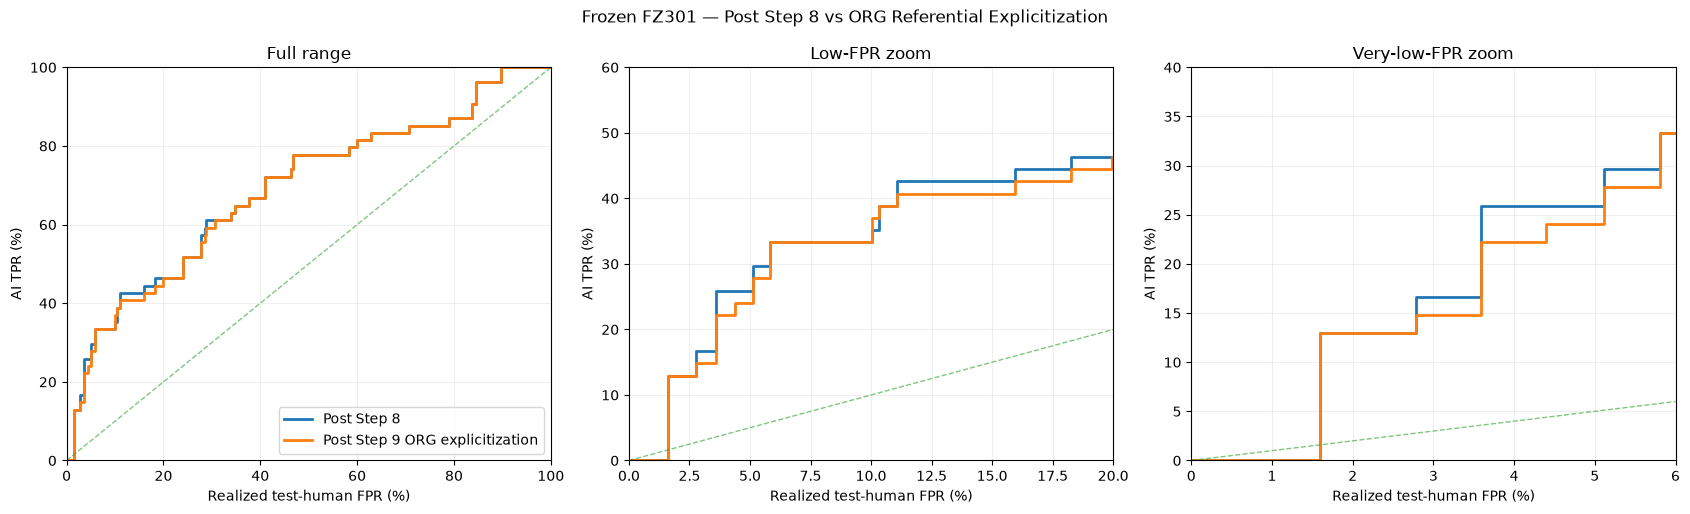

In [8]:
# Frozen-FZ301 evaluation after ORG Referential Explicitization.

def extension_frame(texts, desc="texts", batch_size=64):
    rows = []

    texts = list(map(str, texts))

    for i, doc in enumerate(
        nlp.pipe(texts, batch_size=batch_size)
    ):
        rows.append(extension_vector(doc))

        if (i + 1) % 50 == 0 or i + 1 == len(texts):
            print(f"{desc}: {i+1}/{len(texts)}")

    return pd.DataFrame(np.vstack(rows), columns=EXT_NAMES)

F301 = list(C04_MANIFEST["feature_names"])

before_files = sorted(
    C04_RUN.glob("*post_step_8_features.csv")
)
assert len(before_files) == 1, before_files

X_before = (
    pd.read_csv(before_files[0])
    .set_index("case_id")
    .loc[step9_cases.case_id, F301]
    .reset_index(drop=True)
)

after_118 = fz118_frame(step9_cases.text.tolist())
after_ext = extension_frame(
    step9_cases.text.tolist(),
    desc="C04b Step 9",
)

X_after = pd.concat(
    [after_118, after_ext],
    axis=1,
)[F301]

assert X_after.shape == (54, 301)

raid_ext = (
    pd.read_parquet(CACHE / "raid_extensions.parquet")
    .set_index("source_id")
    .loc[raid.source_id, EXT_NAMES]
    .reset_index(drop=True)
)

XR = pd.concat(
    [
        raid[FEATURE_NAMES].reset_index(drop=True),
        raid_ext,
    ],
    axis=1,
)[F301]

mix = step9_cases.domain.value_counts(normalize=True)

def human_mask(split):
    return (
        raid.split.eq(split)
        & raid.label.eq(0)
        & raid.domain.isin(mix.index)
    ).to_numpy()

calmask = human_mask("validation")
hmask = human_mask("test")

def genre_weights(mask):
    g = raid.loc[mask, "domain"]
    counts = g.value_counts()

    w = np.asarray(
        [mix[x] / counts[x] for x in g],
        dtype=float,
    )

    assert np.isclose(w.sum(), 1.0)
    return w

wc = genre_weights(calmask)
wh = genre_weights(hmask)

cal_scores = fz301.predict_proba(
    XR.loc[calmask, F301]
)[:, 1]

human_scores = fz301.predict_proba(
    XR.loc[hmask, F301]
)[:, 1]

before_scores = fz301.predict_proba(
    X_before[F301]
)[:, 1]

after_scores = fz301.predict_proba(
    X_after[F301]
)[:, 1]

def weighted_auc(ai_scores):
    fpr, tpr, _ = roc_curve(
        np.r_[
            np.zeros(len(human_scores)),
            np.ones(len(ai_scores)),
        ],
        np.r_[human_scores, ai_scores],
        sample_weight=np.r_[
            wh,
            np.ones(len(ai_scores)) / len(ai_scores),
        ],
        drop_intermediate=False,
    )

    return auc(fpr, tpr)

eval_summary = pd.DataFrame([
    {
        "stage": "Post Step 8",
        "AUROC": weighted_auc(before_scores),
        "mean_AI_score": before_scores.mean(),
        "median_AI_score": np.median(before_scores),
    },
    {
        "stage": "Post Step 9 ORG explicitization",
        "AUROC": weighted_auc(after_scores),
        "mean_AI_score": after_scores.mean(),
        "median_AI_score": np.median(after_scores),
    },
])

eval_summary["AUROC_change_vs_step8"] = (
    eval_summary.AUROC - eval_summary.iloc[0].AUROC
)

eval_summary["mean_score_change_vs_step8"] = (
    eval_summary.mean_AI_score
    - eval_summary.iloc[0].mean_AI_score
)

eval_summary.to_csv(
    OUT / "evaluation_summary.csv",
    index=False,
)

display(eval_summary)

cuts = np.r_[
    np.inf,
    np.unique(cal_scores)[::-1],
    -np.inf,
]

stair = pd.DataFrame({
    "threshold": cuts,
    "calibration_FPR": [
        wc[cal_scores > c].sum()
        for c in cuts
    ],
    "test_FPR": [
        wh[human_scores > c].sum()
        for c in cuts
    ],
    "Post Step 8": [
        (before_scores > c).mean()
        for c in cuts
    ],
    "Post Step 9 ORG explicitization": [
        (after_scores > c).mean()
        for c in cuts
    ],
})

stair.to_csv(
    OUT / "detailed_TPR_staircase.csv",
    index=False,
)

fig, axs = plt.subplots(1, 3, figsize=(17, 5.2))

panels = [
    ((0, 100), (0, 100), "Full range"),
    ((0, 20), (0, 60), "Low-FPR zoom"),
    ((0, 6), (0, 40), "Very-low-FPR zoom"),
]

for ax, (xlim, ylim, title) in zip(axs, panels):
    for label in [
        "Post Step 8",
        "Post Step 9 ORG explicitization",
    ]:
        ax.step(
            stair["test_FPR"] * 100,
            stair[label] * 100,
            where="post",
            linewidth=2,
            label=label,
        )

    hi = min(xlim[1], ylim[1])

    ax.plot(
        [0, hi],
        [0, hi],
        "--",
        linewidth=1,
        alpha=0.6,
    )

    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_xlabel("Realized test-human FPR (%)")
    ax.set_ylabel("AI TPR (%)")
    ax.set_title(title)
    ax.grid(alpha=0.2)

axs[0].legend(loc="lower right")

fig.suptitle(
    "Frozen FZ301 — Post Step 8 vs ORG Referential Explicitization"
)

fig.tight_layout()

for folder in [OUT, FIG]:
    fig.savefig(
        folder / "C04b_FZ301_step8_vs_ORG_explicitization_TPR_staircase.pdf",
        bbox_inches="tight",
    )
    fig.savefig(
        folder / "C04b_FZ301_step8_vs_ORG_explicitization_TPR_staircase.png",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()

ORG contribution movement:


,feature,Step8_gap,Step9_gap,Step9_minus_Step8,Step9_ci_low,Step9_ci_high
230,ner_ORG_entity_share,0.000600,0.000437,-0.000163,-0.000358,0.001231
231,ner_ORG_sentence_mean,0.002614,0.002280,-0.000335,0.000697,0.004054
232,ner_ORG_sentence_std,0.002801,0.001985,-0.000816,0.000072,0.003935
233,ner_ORG_sentence_max,0.002142,0.001529,-0.000614,-0.000165,0.003177



Largest contribution changes:


,feature,Step8_gap,Step9_gap,Step9_minus_Step8
232,ner_ORG_sentence_std,0.002801,0.001985,-0.000816
233,ner_ORG_sentence_max,0.002142,0.001529,-0.000614
231,ner_ORG_sentence_mean,0.002614,0.002280,-0.000335
262,coref_repeated_mention_share,0.000309,0.000533,0.000225
115,and_conjunction_word_unigram_overlap,0.000278,0.000097,-0.000182
261,coref_repeated_cluster_share,0.000077,0.000253,0.000176
238,ner_PERSON_entity_share,0.001123,0.000949,-0.000173
230,ner_ORG_entity_share,0.000600,0.000437,-0.000163
88,pos_1gram_overlap_bin_3,-0.000019,0.000144,0.000163
27,punct_relative_comma,0.000185,0.000327,0.000143


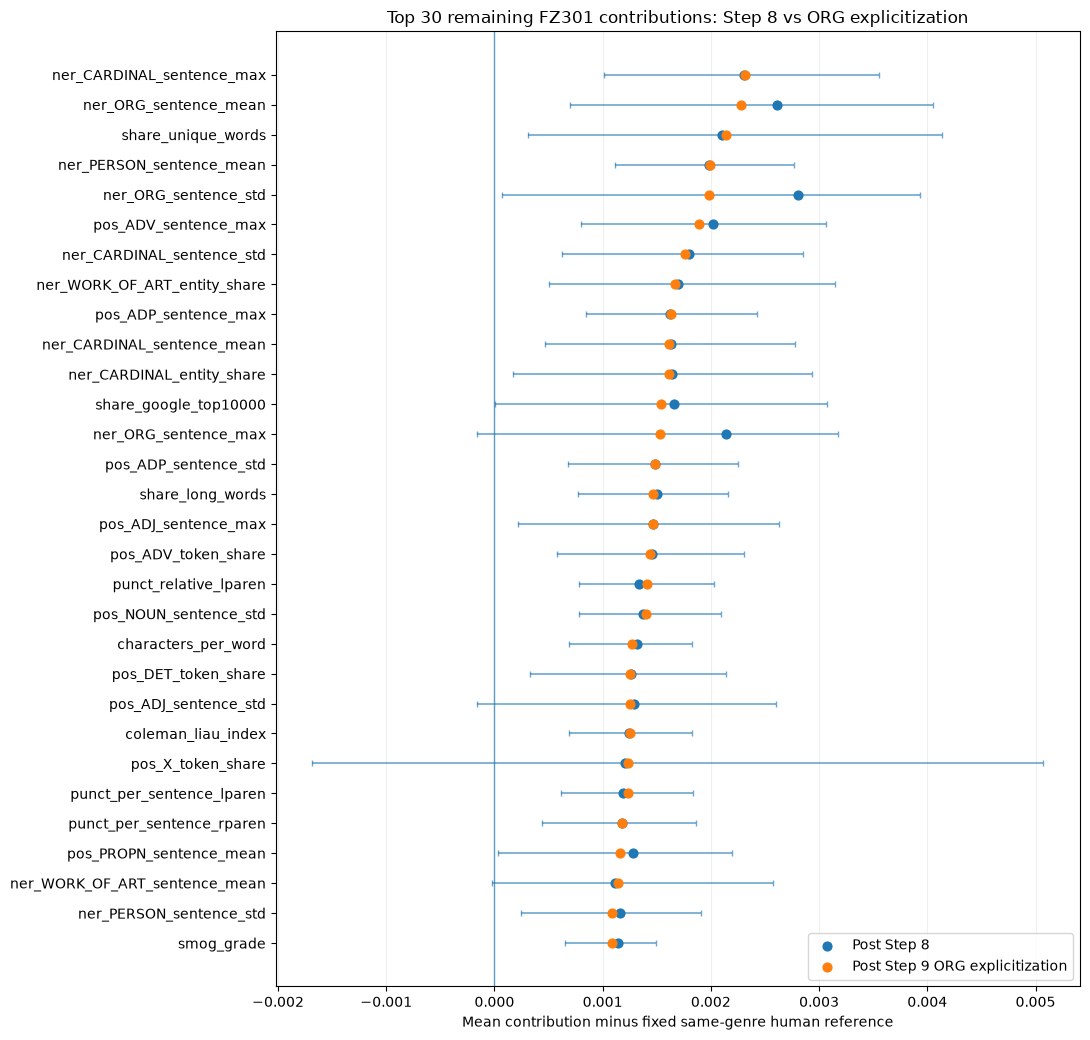

In [9]:
# Contribution movement: Step 8 vs C04b Step 9.

def forest_contributions(model, frame):
    X = np.asarray(frame, dtype=np.float32)
    output = np.zeros_like(X, dtype=float)
    bias = 0.0

    for estimator in model.estimators_:
        tree = estimator.tree_
        value = tree.value[:, 0, :].astype(float)
        prob = value[:, 1] / value.sum(axis=1)

        bias += prob[0] / len(model.estimators_)

        for i, row in enumerate(X):
            node = 0

            while (
                tree.children_left[node]
                != tree.children_right[node]
            ):
                feature = tree.feature[node]

                child = (
                    tree.children_left[node]
                    if row[feature] <= tree.threshold[node]
                    else tree.children_right[node]
                )

                output[i, feature] += (
                    prob[child] - prob[node]
                ) / len(model.estimators_)

                node = child

    np.testing.assert_allclose(
        bias + output.sum(axis=1),
        model.predict_proba(frame)[:, 1],
        atol=1e-8,
        rtol=0,
    )

    return output

before_contrib = forest_contributions(
    fz301,
    X_before[F301],
)

after_contrib = forest_contributions(
    fz301,
    X_after[F301],
)

human_contrib = forest_contributions(
    fz301,
    XR.loc[hmask, F301],
)

human_ref = (
    pd.DataFrame(
        human_contrib,
        columns=F301,
    )
    .assign(
        domain=raid.loc[hmask, "domain"].to_numpy()
    )
    .groupby("domain")[F301]
    .mean()
)

ref = human_ref.loc[step9_cases.domain].to_numpy()

before_gap = before_contrib - ref
after_gap = after_contrib - ref

rng = np.random.default_rng(SEED)
boot = np.zeros((B, len(F301)), dtype=float)

for domain in sorted(mix.index):
    ix = np.flatnonzero(
        step9_cases.domain.to_numpy() == domain
    )

    draw = rng.choice(
        ix,
        size=(B, len(ix)),
        replace=True,
    )

    boot += (
        len(ix) / 54.0
    ) * after_gap[draw].mean(axis=1)

lo, hi = np.quantile(
    boot,
    [0.025, 0.975],
    axis=0,
)

compare = pd.DataFrame({
    "feature": F301,
    "Step8_gap": before_gap.mean(axis=0),
    "Step9_gap": after_gap.mean(axis=0),
    "Step9_ci_low": lo,
    "Step9_ci_high": hi,
})

compare["Step9_minus_Step8"] = (
    compare["Step9_gap"]
    - compare["Step8_gap"]
)

compare["abs_change"] = compare["Step9_minus_Step8"].abs()

compare.to_csv(
    OUT / "step8_vs_step9_contributions.csv",
    index=False,
)

print("ORG contribution movement:")

display(
    compare.loc[
        compare.feature.isin(ORG_FEATURES)
    ][
        [
            "feature",
            "Step8_gap",
            "Step9_gap",
            "Step9_minus_Step8",
            "Step9_ci_low",
            "Step9_ci_high",
        ]
    ]
)

print("\nLargest contribution changes:")

display(
    compare
    .sort_values("abs_change", ascending=False)
    .head(20)[
        [
            "feature",
            "Step8_gap",
            "Step9_gap",
            "Step9_minus_Step8",
        ]
    ]
)

top = (
    compare
    .sort_values("Step9_gap", ascending=False)
    .head(30)
    .iloc[::-1]
    .reset_index(drop=True)
)

y = np.arange(len(top))
current = top["Step9_gap"].to_numpy(float)

xerr = np.vstack([
    current - top["Step9_ci_low"].to_numpy(float),
    top["Step9_ci_high"].to_numpy(float) - current,
])

fig, ax = plt.subplots(figsize=(11, 10.5))

ax.errorbar(
    current,
    y,
    xerr=xerr,
    fmt="none",
    capsize=2,
    linewidth=1.2,
    alpha=0.65,
)

ax.scatter(
    top["Step8_gap"],
    y,
    label="Post Step 8",
    s=40,
    zorder=3,
)

ax.scatter(
    top["Step9_gap"],
    y,
    label="Post Step 9 ORG explicitization",
    s=40,
    zorder=4,
)

ax.axvline(0, linewidth=1, alpha=0.7)

ax.set_yticks(y)
ax.set_yticklabels(top["feature"])

ax.set_xlabel(
    "Mean contribution minus fixed same-genre human reference"
)

ax.set_title(
    "Top 30 remaining FZ301 contributions: "
    "Step 8 vs ORG explicitization"
)

ax.legend()
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()

for folder in [OUT, FIG]:
    fig.savefig(
        folder / "C04b_FZ301_step8_vs_ORG_explicitization_contributions.pdf",
        bbox_inches="tight",
    )
    fig.savefig(
        folder / "C04b_FZ301_step8_vs_ORG_explicitization_contributions.png",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()

In [10]:
# C04b — inspect why ORG explicitization candidates are being rejected.

print("Total generated candidates:", len(generated_candidates))
print(
    "Guard-valid candidates:",
    int(generated_candidates["valid"].astype(bool).sum()),
)

print(
    "Cases represented:",
    generated_candidates["case_id"].nunique(),
)

print("\n=== REJECTION REASONS ===")

rejection_summary = (
    generated_candidates.loc[
        ~generated_candidates["valid"].astype(bool)
    ]
    .groupby("rejection_reason")
    .agg(
        n=("case_id", "size"),
        n_cases=("case_id", "nunique"),
    )
    .sort_values(
        "n",
        ascending=False,
    )
)

display(rejection_summary)


print("\n=== PROMPT / GENERATION COVERAGE BY CASE ===")

case_diag = (
    prompt_manifest
    .groupby(
        ["case_id", "domain"]
    )
    .size()
    .rename("n_prompts")
    .reset_index()
)

generated_diag = (
    generated_candidates
    .groupby("case_id")
    .agg(
        n_generated=(
            "candidate_sentence",
            "size",
        ),

        n_valid=(
            "valid",
            lambda x:
                x.astype(bool).sum(),
        ),
    )
    .reset_index()
)

case_diag = (
    case_diag
    .merge(
        generated_diag,
        on="case_id",
        how="left",
    )
    .fillna(
        {
            "n_generated": 0,
            "n_valid": 0,
        }
    )
)

display(
    case_diag.sort_values(
        [
            "n_valid",
            "n_generated",
        ],
        ascending=[
            True,
            False,
        ],
    )
)


# ------------------------------------------------------------
# Show representative rejected generations for each major reason.
# ------------------------------------------------------------

major_reasons = (
    generated_candidates.loc[
        ~generated_candidates["valid"].astype(bool),
        "rejection_reason",
    ]
    .value_counts()
    .head(12)
    .index
    .tolist()
)


for reason in major_reasons:

    subset = (
        generated_candidates.loc[
            generated_candidates[
                "rejection_reason"
            ].eq(reason)
        ]
        .head(5)
    )

    print(
        "\n"
        + "=" * 110
    )

    print(
        "REJECTION:",
        reason,
        "| total =",
        int(
            generated_candidates[
                "rejection_reason"
            ].eq(reason).sum()
        ),
    )

    for row in subset.itertuples(
        index=False
    ):

        print(
            "\n",
            row.case_id,
            "|",
            row.domain,
            "| ORG:",
            row.target_org,
        )

        print(
            "SOURCE:",
            row.source_sentence,
        )

        print(
            "GENERATED:",
            row.candidate_sentence,
        )


# ------------------------------------------------------------
# Show the one/few candidates that actually passed all guards.
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 110
)

print(
    "GUARD-VALID CANDIDATES"
)

valid_view = (
    generated_candidates.loc[
        generated_candidates[
            "valid"
        ].astype(bool)
    ]
)

if len(valid_view) == 0:

    print(
        "NONE"
    )

else:

    for row in valid_view.itertuples(
        index=False
    ):

        print(
            "\n",
            row.case_id,
            "|",
            row.domain,
            "| ORG:",
            row.target_org,
        )

        print(
            "SOURCE:",
            row.source_sentence,
        )

        print(
            "GENERATED:",
            row.candidate_sentence,
        )

        print(
            "content recall:",
            getattr(
                row,
                "content_lemma_recall",
                None,
            ),
            "| length ratio:",
            getattr(
                row,
                "length_ratio",
                None,
            ),
        )

Total generated candidates: 391
Guard-valid candidates: 38
Cases represented: 12

=== REJECTION REASONS ===


,n,n_cases
rejection_reason,,
target_surface_not_plus_one,270,12
detected_ORG_not_increased,23,7
length_ratio,15,4
sentence_count_changed,14,4
too_many_added_content_lemmas,9,4
new_entity:later blue merle,4,1
lost_entity:the national library of,2,1
lost_entity:3rd,2,1
lost_entity:skype and zoom,2,1



=== PROMPT / GENERATION COVERAGE BY CASE ===


,case_id,domain,n_prompts,n_generated,n_valid
1,gate_0017,news,4,32,0
3,gate_0030,news,2,16,0
4,gate_0039,wiki,1,8,0
6,gate_0054,news,1,8,0
9,gate_0082,wiki,6,48,1
11,gate_0094,news,4,32,1
7,gate_0075,books,1,8,1
0,gate_0007,wiki,10,80,2
8,gate_0076,news,3,24,2
10,gate_0086,wiki,7,56,9



REJECTION: target_surface_not_plus_one | total = 270

 gate_0007 | wiki | ORG: Treasury
SOURCE: Sir John Maitland was a member of a prominent Scottish family, serving as a Lord of Session, a Lord of the Articles, and a Lord Commissioner of the Treasury.
GENERATED: Sir John Maitland was a member of a prominent Scottish family, serving as a Lord of Session, a Lord of the Articles, and a Lord Commissioner of the Treasury.

 gate_0007 | wiki | ORG: Treasury
SOURCE: Sir John Maitland was a member of a prominent Scottish family, serving as a Lord of Session, a Lord of the Articles, and a Lord Commissioner of the Treasury.
GENERATED: Sir John Maitland was a member of a prominent Scottish family, serving as a Lord of Session, a Lord of the Articles, and as a Lord Commissioner of the Treasury.

 gate_0007 | wiki | ORG: Treasury
SOURCE: Sir John Maitland was a member of a prominent Scottish family, serving as a Lord of Session, a Lord of the Articles, and a Lord Commissioner of the Treasury.
GE